# Лабораторная работа №3. Транскрипция (G2P)

**Цель работы:** разработка модуля преобразования графем в фонемы (G2P) 
для русского языка и подготовка фонетической транскрипции для обучения моделей.

**Курс:** Синтез Речи, Университет ИТМО, 2026

**Выполнила:** Ходжаметова Милана

## 1. Предобработка данных

Данные подготовлены скриптом `prepare_lexicon.py`, который обрабатывает `.TextGrid`-разметку MFA из `data/RUSLAN_align_v2/` и формирует:

- `data/tokens_phones.csv` — таблица «токен-фонемы» без пауз
- `data/tokens_phones_sil.csv` — то же, но с токенами `<SIL>`
- `data/lexicon.csv` — словарь произношений по train-части

In [8]:
from pathlib import Path
import pandas as pd

LAB_DIR = Path("/home/ext-khodzhametova@ad.speechpro.com/speech_synthesis/tts_labs_itmo/labs/lab3_g2p")
DATA = LAB_DIR / "data"

tokens = pd.read_csv(DATA / "tokens_phones.csv", sep="|", dtype=str).fillna("")
tokens_sil = pd.read_csv(DATA / "tokens_phones_sil.csv", sep="|", dtype=str).fillna("")
lexicon = pd.read_csv(DATA / "lexicon.csv", sep="|", dtype=str).fillna("")

summary = pd.DataFrame({
    "Показатель": [
        "Предложений всего",
        "Предложений train",
        "Предложений test",
        "Токенов без пауз",
        "Токенов с паузами",
        "Пауз <SIL>",
        "Записей в словаре",
        "Слов с несколькими произношениями",
    ],
    "Значение": [
        tokens["id"].nunique(),
        tokens[tokens["set"] == "train"]["id"].nunique(),
        tokens[tokens["set"] == "test"]["id"].nunique(),
        len(tokens),
        len(tokens_sil),
        (tokens_sil["phones"] == "<SIL>").sum(),
        len(lexicon),
        (lexicon.groupby("word")["phones"].nunique() > 1).sum(),
    ],
})

summary

,Показатель,Значение
0,Предложений всего,16132
1,Предложений train,12902
2,Предложений test,3230
3,Токенов без пауз,170182
4,Токенов с паузами,209150
5,Пауз <SIL>,38968
6,Записей в словаре,34418
7,Слов с несколькими произношениями,487


## 2. Разведочный анализ фонемного инвентаря

Анализ состава фонем корпуса RUSLAN: частоты, редкие фонемы, длительности, 
OOV-слова, омографы и сопоставление с целевым набором `common/phones_mfa.txt`.

### 2.1. Частотный анализ фонем

Собираем все фонемы из колонки `phones` файла `tokens_phones.csv` 
(без пауз — `<SIL>` в этом файле отсутствует) и считаем их частоты.

In [9]:
from collections import Counter

# Собираем все фонемы корпуса (без пауз, файл tokens_phones.csv)
all_phones = []
for transcription in tokens["phones"]:
    all_phones.extend(transcription.split())

phone_counts = Counter(all_phones)
total = sum(phone_counts.values())

phone_df = (
    pd.DataFrame(phone_counts.items(), columns=["Фонема", "Частота"])
    .sort_values("Частота", ascending=False)
    .reset_index(drop=True)
)
phone_df["Доля, %"] = phone_df["Частота"] / total * 100

print(f"Всего фонем:      {total}")
print(f"Уникальных фонем: {len(phone_counts)}")
print()
display(phone_df)

Всего фонем:      968357
Уникальных фонем: 55



,Фонема,Частота,"Доля, %"
0,ɪ,80121,8.273911
1,ə,74050,7.646973
2,ɐ,50254,5.189615
3,a,42238,4.361821
4,t̪,41717,4.308019
5,n̪,38054,3.929749
6,j,37552,3.877909
7,e,33691,3.479192
8,s̪,32358,3.341536
9,r,31392,3.241780


In [12]:
# В каких предложениях есть spn
spn_mask = tokens["phones"].str.split().apply(lambda ps: "spn" in ps)
spn_ids = tokens.loc[spn_mask, "id"].unique()

print("Всего предложений со spn:", len(spn_ids))
print("Токенов со spn:          ", spn_mask.sum())
print()
print("Доля предложений со spn:", round(len(spn_ids) / tokens['id'].nunique() * 100, 2), "%")

#  примеры
spn_examples = tokens[spn_mask].head(10)
display(spn_examples[["id", "token", "phones"]])

Всего предложений со spn: 1266
Токенов со spn:           1388

Доля предложений со spn: 7.85 %


,id,token,phones
4684,000813_RUSLAN,ленински,spn
7862,001365_RUSLAN,джасис,spn
7865,001366_RUSLAN,джасис,spn
8402,001467_RUSLAN,застежку,spn
9643,001706_RUSLAN,супрематиста,spn
11835,002159_RUSLAN,исправительно,spn
16887,003016_RUSLAN,хиллс,spn
16923,003020_RUSLAN,мидоу,spn
16931,003022_RUSLAN,хиллс,spn
19886,003528_RUSLAN,селектрик-композер,spn


In [15]:
# --- Фильтрация предложений со spn ---

spn_mask = tokens["phones"].str.split().apply(lambda ps: "spn" in ps)
spn_ids = set(tokens.loc[spn_mask, "id"].unique())

print(f"Найдено предложений со spn: {len(spn_ids)}")
print(f"Доля от всех предложений:   {len(spn_ids) / tokens['id'].nunique() * 100:.2f}%")
print()

tokens_clean = tokens[~tokens["id"].isin(spn_ids)].copy()
tokens_sil_clean = tokens_sil[~tokens_sil["id"].isin(spn_ids)].copy()

print("После фильтрации:")
print(f"  Предложений:           {tokens_clean['id'].nunique()}")
print(f"  Токенов без пауз:      {len(tokens_clean)}")
print(f"  Токенов с паузами:     {len(tokens_sil_clean)}")

# Пересчитываем частоты фонем уже без spn
all_phones = []
for transcription in tokens_clean["phones"]:
    all_phones.extend(transcription.split())

phone_counts = Counter(all_phones)
total = sum(phone_counts.values())

phone_df = (
    pd.DataFrame(phone_counts.items(), columns=["Фонема", "Частота"])
    .sort_values("Частота", ascending=False)
    .reset_index(drop=True)
)
phone_df["Доля, %"] = phone_df["Частота"] / total * 100

print()
print(f"Всего фонем после фильтрации:      {total}")
print(f"Уникальных фонем после фильтрации: {len(phone_counts)}")
print()
display(phone_df.head(10))
display(phone_df.tail(10))

Найдено предложений со spn: 1266
Доля от всех предложений:   7.85%

После фильтрации:
  Предложений:           14866
  Токенов без пауз:      152521
  Токенов с паузами:     187225

Всего фонем после фильтрации:      875969
Уникальных фонем после фильтрации: 54



,Фонема,Частота,"Доля, %"
0,ɪ,72544,8.281572
1,ə,67010,7.649814
2,ɐ,45614,5.207262
3,a,38066,4.345588
4,t̪,37897,4.326295
5,n̪,34561,3.945459
6,j,33972,3.878219
7,e,30547,3.487224
8,s̪,29252,3.339388
9,r,28577,3.262330


,Фонема,Частота,"Доля, %"
44,ɟ,2488,0.284028
45,æ,2384,0.272156
46,ʉ,1725,0.196925
47,fʲ,1305,0.148978
48,ɵ,674,0.076943
49,ç,357,0.040755
50,tʂ,182,0.020777
51,dʐ,167,0.019065
52,ʑ,16,0.001827
53,ɣ,10,0.001142


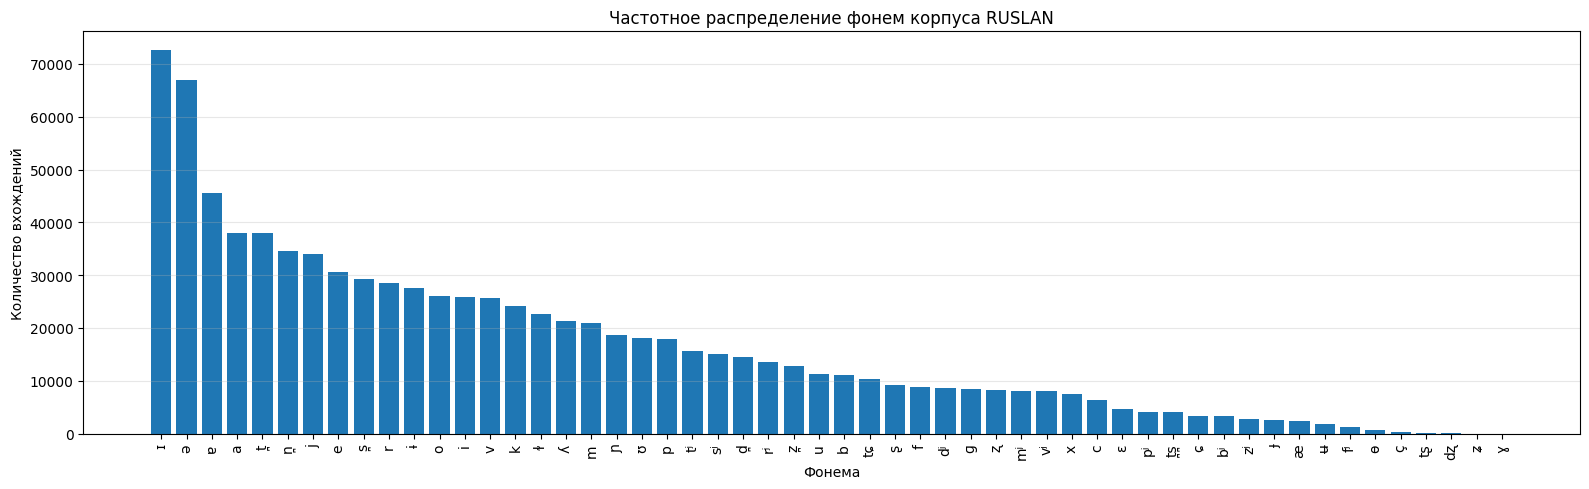

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 5))
plt.bar(phone_df["Фонема"], phone_df["Частота"])
plt.title("Частотное распределение фонем корпуса RUSLAN")
plt.xlabel("Фонема")
plt.ylabel("Количество вхождений")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# 1. Самые редкие фонемы 
rare_df = phone_df[phone_df["Частота"] < 500].reset_index(drop=True)
print(f"Редких фонем (< 500 вхождений): {len(rare_df)}")
print()
display(rare_df)

# 2. Примеры 
print("\nПримеры употребления редких фонем:\n")
examples = []
for phone in rare_df["Фонема"]:
    matches = tokens_clean[
        tokens_clean["phones"].str.split().apply(lambda ps: phone in ps)
    ]
    for _, row in matches.head(5).iterrows():
        examples.append({
            "Фонема": phone,
            "Слово": row["token"],
            "Транскрипция": row["phones"],
            "ID": row["id"],
        })

examples_df = pd.DataFrame(examples)
display(examples_df)

Редких фонем (< 500 вхождений): 5



,Фонема,Частота,"Доля, %"
0,ç,357,0.040755
1,tʂ,182,0.020777
2,dʐ,167,0.019065
3,ʑ,16,0.001827
4,ɣ,10,0.001142



Примеры употребления редких фонем:



,Фонема,Слово,Транскрипция,ID
0,ç,эпохи,ɪ p o ç ɪ,000207_RUSLAN
1,ç,стихи,sʲ tʲ ɪ ç i,000421_RUSLAN
2,ç,плохие,p ɫ ɐ ç i j e,000504_RUSLAN
3,ç,стихийными,sʲ tʲ ɪ ç i j n̪ ɨ mʲ ɪ,000613_RUSLAN
4,ç,схеме,s̪ ç e mʲ e,000897_RUSLAN
5,tʂ,лучше,ɫ u tʂ ɨ,000156_RUSLAN
6,tʂ,худшие,x u tʂ ɨ j e,000192_RUSLAN
7,tʂ,лучше,ɫ u tʂ ɨ,000298_RUSLAN
8,tʂ,лучшие,ɫ u tʂ ɨ j e,000738_RUSLAN
9,tʂ,лучше,ɫ u tʂ ɨ,000799_RUSLAN


### 2.2. Редкие фонемы

В корпусе выделяются **5 фонем с частотой менее 500 вхождений**:

| Фонема | Частота | Примеры слов | Комментарий |
|---|---|---|---|
| `ç` | 357 | `эпохи`, `стихи`, `схеме` | мягкий аллофон `x` перед гласными переднего ряда |
| `tʂ` | 182 | `лучше`, `худшие`, `сумасшедший` | слитное произношение сочетаний `тш` / `чш` |
| `dʐ` | 167 | `джинсы`, `пиджак`, `джон` | слитное `дж` в заимствованиях |
| `ʑ` | 16 | `уезжал`, `приезжал`, `зажженную` | мягкое `ж` как результат ассимиляции |
| `ɣ` | 10 | `бухгалтер`, `сверхсрочник` | фрикативное `г` (книжное / южнорусское) |

**Вывод:** редкие фонемы — не ошибки разметки, а реальные аллофоны русского языка 
в специфических контекстах (заимствования, ассимиляция, мягкие варианты согласных). 
Все они присутствуют в целевом инвентаре `common/phones_mfa.txt`, поэтому **сохраняются 
без изменений**. Удалять их нецелесообразно: это исказит эталонную разметку. 
Модель G2P должна уметь их предсказывать, что мы проверим по метрике PER.

In [18]:
# OOV-анализ на train+test 
lexicon_words = set(lexicon["word"].unique())

# MFA-словарь
mfa_words = set()
with open(DATA / "russian_mfa.dict", encoding="utf-8") as f:
    for line in f:
        parts = line.rstrip("\n").split("\t")
        if parts and parts[0]:
            mfa_words.add(parts[0])

print(f"Слов в lexicon (train):  {len(lexicon_words)}")
print(f"Слов в russian_mfa.dict: {len(mfa_words)}")
print()

# Уникальные слова в корпусе
corpus_words = set(tokens_clean["token"].unique())
corpus_words.discard("")  # пустые токены 

print(f"Уникальных слов в корпусе (без spn): {len(corpus_words)}")
print()

oov_lex = corpus_words - lexicon_words
oov_mfa = corpus_words - mfa_words
oov_both = corpus_words - lexicon_words - mfa_words

print(f"OOV относительно lexicon:          {len(oov_lex)} ({len(oov_lex)/len(corpus_words)*100:.2f}%)")
print(f"OOV относительно russian_mfa.dict: {len(oov_mfa)} ({len(oov_mfa)/len(corpus_words)*100:.2f}%)")
print(f"OOV относительно обоих словарей:    {len(oov_both)} ({len(oov_both)/len(corpus_words)*100:.2f}%)")
print()
print("Примеры OOV относительно обоих словарей:")
print(sorted(oov_both)[:30])

Слов в lexicon (train):  33899
Слов в russian_mfa.dict: 452401

Уникальных слов в корпусе (без spn): 36539

OOV относительно lexicon:          4446 (12.17%)
OOV относительно russian_mfa.dict: 5831 (15.96%)
OOV относительно обоих словарей:    924 (2.53%)

Примеры OOV относительно обоих словарей:
['абрикосовым', 'авангардиста', 'авиационной', 'автобиографическом', 'аккордно', 'александрова', 'александрову', 'алешковича', 'альбертовна', 'альбертовну', 'аляповатым', 'амстердама', 'ананьева', 'андрее', 'андрюшины', 'анодированным', 'антибольшевизмом', 'антипов', 'антисоветские', 'антисоветское', 'антисоветчину', 'аптекарские', 'ардисом', 'арифметическим', 'армейскими', 'архаистами', 'архалук', 'арьеву', 'бадвайзер', 'байковые']


### 2.3. OOV-анализ

| Словарь | Слов |
|---|---|
| `lexicon.csv` (train) | 33 899 |
| `russian_mfa.dict` | 452 401 |
| уникальных слов в корпусе (без `spn`) | 36 539 |

| Относительно | OOV-слов | Доля |
|---|---|---|
| `lexicon.csv` (train) | 4 446 | 12.17% |
| `russian_mfa.dict` | 5 831 | 15.96% |
| обоих словарей (residual OOV) | 924 | **2.53%** |

**Вывод:** 87.8% слов корпуса находятся в обучающем словаре `lexicon.csv` — их транскрипция 
берётся напрямую. Ещё 9.6% покрывает `russian_mfa.dict`. Остаётся **924 residual OOV-слова 
(2.53%)**, для которых работает только фонетическая модель — именно на этой подгруппе 
оценивается PER OOV (порог ≤ 0.20).

Примеры residual OOV: имена собственные (`александрова`, `андрее`, `антипов`), 
заимствования (`бадвайзер`, `архалук`), редкие формы (`авангардиста`, `антисоветчину`).

In [19]:
# Омографы
multi = (
    lexicon.groupby("word")["phones"]
    .nunique()
    .loc[lambda s: s > 1]
    .sort_values(ascending=False)
)

print(f"Слов с несколькими произношениями: {len(multi)}")
print()
display(multi.head(20).to_frame("Вариантов произношения"))

Слов с несколькими произношениями: 487



,Вариантов произношения
word,
с,6
в,5
чмутов,5
эви,4
из,4
гонзалес,4
цека,3
хуберт,3
хемингуэя,3


In [20]:
for word in ["замок", "все", "всё", "мука", "дорога", "атлас", "орган"]:
    variants = lexicon[lexicon["word"] == word]
    if len(variants) == 0:
        print(f"\n'{word}': нет в lexicon")
        continue
    print(f"\n'{word}': {len(variants)} вариант(ов)")
    display(variants[["word", "phones", "count"]])


'замок': 2 вариант(ов)


,word,phones,count
8503,замок,z̪ a m ə k,1
8504,замок,z̪ ɐ m o k,1



'все': 2 вариант(ов)


,word,phones,count
3690,все,f sʲ ɵ,447
3691,все,f sʲ e,263



'всё': нет в lexicon

'мука': 2 вариант(ов)


,word,phones,count
14738,мука,m ʊ k a,3
14739,мука,m u k ə,1



'дорога': 2 вариант(ов)


,word,phones,count
6837,дорога,d̪ ɐ r o ɡ ə,7
6838,дорога,d̪ ə r ɐ ɡ a,2



'атлас': нет в lexicon

'орган': 1 вариант(ов)


,word,phones,count
17925,орган,o r ɡ ə n̪,2


### 2.4. Омографы и ударение

В словаре **487 слов** имеют несколько вариантов произношения.

**Классические омографы в корпусе:**

| Слово | Варианты | Частоты | Комментарий |
|---|---|---|---|
| `замок` | `z̪ a m ə k` / `z̪ ɐ m o k` | 1 / 1 | за́мок / замо́к — частоты равны, выбор невозможен по частоте |
| `все` | `f sʲ ɵ` / `f sʲ e` | 447 / 263 | всё / все — «ё» в графемах потеряна, но фонетика сохранила |
| `мука` | `m ʊ k a` / `m u k ə` | 3 / 1 | мука́ / му́ка |
| `дорога` | `d̪ ɐ r o ɡ ə` / `d̪ ə r ɐ ɡ a` | 7 / 2 | доро́га / дорога́ (архаичн.) |
| `орган` | `o r ɡ ə n̪` | 2 | о́рган и орга́н не различены — ошибка разметки MFA |

**Выводы:**
1. Проблема омографов в корпусе **присутствует**, но её масштаб ограничен: 487 слов из 33 899 (1.4%).
2. В **критических случаях** (например, `замок`) частоты вариантов равны — модель G2P не может 
   выбрать правильный вариант без контекста.
3. **Ударение в фонемном инвентаре MFA не маркируется** — различия омографов выражаются 
   через качество гласной (редуцированная/нередуцированная), что не всегда однозначно.
4. Буква `ё` в графемах нормализована к `е`, что добавляет неоднозначность (`все`/`всё`).

In [21]:
# Целевой инвентарь
target_phones = [
    p.strip() for p in (LAB_DIR.parent.parent / "common" / "phones_mfa.txt")
    .read_text(encoding="utf-8").splitlines()
    if p.strip()
]
target_set = set(target_phones)

# Наблюдаемые фонемы
observed_set = set(phone_counts.keys())

only_observed = observed_set - target_set
only_target = target_set - observed_set
common = observed_set & target_set

print(f"Целевых фонем:     {len(target_set)}")
print(f"Наблюдаемых:       {len(observed_set)}")
print(f"Совпадает:         {len(common)}")
print()
print(f"Только в корпусе (лишние): {sorted(only_observed)}")
print()
print(f"Только в целевом (не встречаются в корпусе): {sorted(only_target)}")

Целевых фонем:     56
Наблюдаемых:       54
Совпадает:         54

Только в корпусе (лишние): []

Только в целевом (не встречаются в корпусе): ['<SIL>', 'd̪z̪']


### 2.5. Сопоставление с целевым инвентарём

| Множество | Фонем |
|---|---|
| Целевой (`common/phones_mfa.txt`) | 56 |
| Наблюдаемый в корпусе (без `spn`) | 54 |
| Совпадает | 54 |
| Только в целевом | `<SIL>`, `d̪z̪` |
| Только в корпусе | — |

**Вывод:** **все 54 наблюдаемые фонемы корпуса уже входят в целевой инвентарь**, 
приведение не требуется. Расхождения:

- `<SIL>` — пауза, отсутствует в `tokens_phones.csv` (без пауз) по определению;
- `d̪z̪` — аффриката, которая ранее встречалась 1 раз в слове `зальцбурге` (в отфильтрованной 
  spn-части). В рабочем корпусе не наблюдается, но модель может её сгенерировать, 
  и целевой инвентарь её допускает.

**Практический вывод для G2P:** выход модели должен принадлежать целевому набору 
`common/phones_mfa.txt`. Поскольку наблюдаемые и целевые фонемы совпадают, 
дополнительных преобразований при транскрипции не требуется — достаточно 
не выходить за пределы инвентаря.

In [1]:
import sys
sys.path.insert(0, "/home/ext-khodzhametova@ad.speechpro.com/speech_synthesis/tts_labs_itmo/labs/lab3_g2p")

from g2p import load_tokens, build_lexicon, load_mfa_dictionary, G2P

tokens = load_tokens()
train = tokens[tokens.set == "train"]
test = tokens[tokens.set == "test"]
lexicon = build_lexicon(train)
mfa_dict = load_mfa_dictionary("/home/ext-khodzhametova@ad.speechpro.com/speech_synthesis/tts_labs_itmo/labs/lab3_g2p/data/russian_mfa.dict")
g2p = G2P(lexicon, mfa_dict)

residual = test[
    ~test.token.str.lower().isin(lexicon)
    & ~test.token.str.lower().isin(mfa_dict)
]

for _, row in residual.head(15).iterrows():
    word = row["token"]
    ref = row["phones"]
    hyp = " ".join(g2p.transcribe([word])[0])
    print(f"{word:30s}")
    print(f"  эталон:      {ref}")
    print(f"  предсказано: {hyp}")
    print()

dropping 1388 tokens without a transcription (0.82%)
чурочку                       
  эталон:      tɕ u r ə tɕ k ʊ
  предсказано: tɕ u r o tɕ k u

клинициста                    
  эталон:      c ʎ i ɲ ɪ t̪s̪ ɨ s̪ t̪ ə
  предсказано: k ʎ i ɲ i t̪s̪ i s̪ t̪ a

квартуполномоченного          
  эталон:      k v ɐ r t̪ u p ə ɫ n̪ ɐ m o tɕ ɪ n̪ ə v ə
  предсказано: k v a r t̪ u p o ɫ n̪ o m o tɕ e n̪ n̪ o ɡ o

андрее                        
  эталон:      ɐ n̪ d̪ rʲ e j e
  предсказано: a n̪ d̪ rʲ e j e

платонове                     
  эталон:      p ɫ ɐ t̪ o n̪ o vʲ e
  предсказано: p ɫ a t̪ o n̪ o vʲ e

шевиотовый                    
  эталон:      ʂ ɨ vʲ ɪ o t̪ ə v ɨ j
  предсказано: ʂ e vʲ i o t̪ o v ɨ j

плачевнее                     
  эталон:      p ɫ ɐ tɕ e v ɲ ɪ j e
  предсказано: p ɫ a tɕ e v ɲ e j e

окончившаяся                  
  эталон:      ɐ k o ɲ tɕ ɪ f ʂ ɐ j a t̪ s̪ ə
  предсказано: o k o n̪ tɕ i f ʂ a j a sʲ a

недолгие                      
  эталон:      ɲ ɪ d̪ o ɫ ɟ ɪ

## 3. Модуль G2P

Реализован в `labs/lab3_g2p/g2p.py`. Логика транскрипции — три уровня:

1. **Словарь RUSLAN** (`lexicon.csv`, train-часть) — самое частое произношение.
2. **Словарь Russian MFA** (`russian_mfa.dict`, 452 401 слово) — первое произношение.
3. **Residual OOV** — правила графемно-фонемного преобразования:
   - базовое соответствие буква → фонема;
   - смягчение согласных перед `е, ё, и, ю, я, ь`;
   - регрессивное оглушение звонких перед глухими и оглушение на конце слова;
   - непроизносимые кластеры (`стн → сн`, `здн → зн`);
   - слияние шипящих (`сч → щ`, `зч → щ`);
   - правило `-ого/-его → -ово/-ево`;
   - **восстановление ударения** через поиск похожего train-слова;
   - **редукция безударных гласных**: `о, а` → `ɐ` (1-й предударный) / `ə` (остальные),
     `е, я, и` → `ɪ`, `у` → `ʊ`.

In [2]:
import subprocess
import sys
from pathlib import Path

LAB_DIR = Path("/home/ext-khodzhametova@ad.speechpro.com/speech_synthesis/tts_labs_itmo/labs/lab3_g2p")

result = subprocess.run(
    [sys.executable, "g2p.py"],
    cwd=LAB_DIR,
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("g2p.py завершился с ошибкой")

dropping 1388 tokens without a transcription (0.82%)
train 135093 tokens / test 33701 tokens
lexicon: 33899 types, 487 with several pronunciations
MFA dictionary: 452401 entries

Calculate metrics, training fold:
running text  PER 0.0075
in-vocabulary PER 0.0075  (135093 words, 100.0%)
OOV           PER nan  word accuracy nan  (0 words, 0.0%)

Calculate metrics, testing fold:
running text  PER 0.0226
in-vocabulary PER 0.0107  (28561 words, 84.7%)
OOV           PER 0.0619  word accuracy 0.7298  (5140 words, 15.3%)

Residual OOV: 1026 tokens, 997 unique words
Residual OOV PER 0.1969
Residual OOV word accuracy 0.2173



## 4. Метаданные для работы №4

Формируем два файла в формате `id | normalized_text | phones`:

- `data/metadata_phones_gt.csv` — эталонная разметка (из `tokens_phones_sil.csv`);
- `data/metadata_phones.csv` — предсказанная разметка (те же токены, 
  но фонемы получены через нашу `G2P`).

Токены пауз обозначены пустым `token` и `<SIL>` в `phones` — при склейке 
`<SIL>` сохраняется на своём месте.

In [3]:
import csv
from pathlib import Path
import pandas as pd

LAB_DIR = Path("/home/ext-khodzhametova@ad.speechpro.com/speech_synthesis/tts_labs_itmo/labs/lab3_g2p")
DATA = LAB_DIR / "data"

# Читаем с паузами, сохраняя пустые токены как пустые строки
tokens_sil = pd.read_csv(
    DATA / "tokens_phones_sil.csv",
    sep="|",
    dtype=str,
    keep_default_na=False,
    quoting=csv.QUOTE_NONE,
)

# Сортируем по предложению и позиции токена
tokens_sil = tokens_sil.sort_values(["id", "token_id"], kind="stable")

print(f"Токенов с паузами:  {len(tokens_sil)}")
print(f"Предложений:        {tokens_sil['id'].nunique()}")
print(f"Пауз <SIL>:         {(tokens_sil['phones'] == '<SIL>').sum()}")
print()

# Собираем предложения
rows_gt = []
for sentence_id, group in tokens_sil.groupby("id", sort=False):
    words = group["token"].tolist()
    phones = group["phones"].tolist()

    # Текст — без пустых токенов (пауз)
    text = " ".join(w for w in words if w != "")
    # Фонемы — все, включая <SIL> от пауз
    phone_seq = " ".join(phones)

    rows_gt.append({"id": sentence_id, "text": text, "phones": phone_seq})

metadata_gt = pd.DataFrame(rows_gt)
print(f"Собрано предложений: {len(metadata_gt)}")
print()
print("Пример:")
print(metadata_gt.head(3).to_string())

Токенов с паузами:  209150
Предложений:        16132
Пауз <SIL>:         38968

Собрано предложений: 16132

Пример:
              id                                                text                                                                                                               phones
0  000000_RUSLAN               с тревожным чувством берусь я за перо                                         s̪ t̪ rʲ ɪ v o ʐ n̪ ɨ m tɕ u s̪ t̪ v ə m bʲ ɪ r u sʲ j a z̪ ə pʲ ɪ r o <SIL>
1  000001_RUSLAN  кого интересуют признания литературного неудачника  k ɐ v o <SIL> ɪ ɲ tʲ ɪ rʲ ɪ s̪ u j ʊ t̪ p rʲ ɪ z̪ n̪ a ɲ e ʎ ɪ tʲ ɪ r ɐ t̪ u r n̪ ə v ə ɲ ɪ ʊ d̪ a tɕ ɲ ɪ k ə <SIL>
2  000002_RUSLAN                    что поучительного в его исповеди                                           ʂ t̪ o p ə ʊ tɕ i tʲ ɪ ʎ n̪ ə v ə f j ɪ v o <SIL> i s̪ p ə vʲ ɪ dʲ ɪ <SIL>
